## Grafy przykładowe

Będziemy wybierać spośród czterech rzeczywistych sieci. W każdym przypadku pomijamy wagi krawędzi.

| Nazwa w kodzie | Co przedstawia graf? | Wierzchołki | Krawędzie |
|:--|:--|--:|--:|
| `www_maly` | **Blogi polityczne**: blogi o polityce amerykańskiej i skierowane odsyłacze między nimi, zebrane w lutym 2005 r. | 1 490 | 19 025 |
| `www_duzy` | **Notre Dame**: strony w domenie nd.edu i skierowane odsyłacze, zebrane w 1999 r. | 325 729 | 1 497 134 |
| `karate` | **Klub karate Zachary’ego**: osoby i nieskierowane relacje towarzyskie między nimi. | 34 | 78 |
| `florencja` | **Rodziny florenckie**: rodziny renesansowej Florencji i nieskierowane powiązania małżeńskie. | 15 | 20 |

Dane blogów pochodzą od L. Adamic i N. Glance, udostępnione przez [Marka Newmana](https://websites.umich.edu/~mejn/netdata/). W tym notatniku powtórzone odsyłacze między tą samą parą blogów łączymy w jedną krawędź; zachowujemy pętle. Stąd 19 025 krawędzi zamiast 19 090 wpisów w pliku.

Graf Notre Dame, zebrany przez R. Albert, H. Jeonga i A.-L. Barabásiego, pobieramy z [kolekcji SNAP](https://snap.stanford.edu/data/web-NotreDame.html). 

Dwa pozostałe grafy są dostępne bez pobierania danych: [`nx.karate_club_graph()`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html) i [`nx.florentine_families_graph()`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.florentine_families_graph.html). W grafie rodzin krawędź oznacza istnienie przynajmniej jednego małżeństwa między dwiema rodzinami; [opis tych danych](https://sites.stat.washington.edu/raftery/Research/PDF/hoff2002.pdf) znajduje się także w pracy Hoffa, Raftery’ego i Handcocka (§4.2).


## Przygotowanie i wybór grafu

Pliki `siec-www-centralnosc.ipynb` i `siec_pomocnicze.py` powinny leżeć w tym samym folderze. Potrzebujemy bibliotek **networkx**, **numpy**, **matplotlib** i **scipy** (używanej przez PageRank). Jeżeli ich brakuje, uruchom w osobnej komórce `%pip install networkx numpy matplotlib scipy`, a następnie zrestartuj kernel.

Funkcje pomocnicze zajmują się pobieraniem i rysowaniem.


In [ ]:
# Importy oraz ustawienia rysunków.
from pathlib import Path
import sys

# Ten warunek pozwala uruchomić notatnik także z katalogu głównego repozytorium.
# Przy pobraniu obu plików do jednego folderu nie trzeba zmieniać ścieżek.
if not Path("siec_pomocnicze.py").exists() and Path("notatniki/src").is_dir():
    sys.path.insert(0, str(Path("notatniki/src").resolve()))

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from siec_pomocnicze import (
    wczytaj_graf, rysuj_graf, rysuj_stopnie, rysuj_scc, rysuj_zasiegi, rysuj_porownanie,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


In [ ]:
# Wybór: "www_maly", "www_duzy", "karate", "florencja".
nazwa = "www_maly"
G = wczytaj_graf(nazwa)

print(f"Graf: {nazwa}")
print(f"Wierzchołki: {G.number_of_nodes():,}; krawędzie: {G.number_of_edges():,}")
print("Skierowany:", G.is_directed())

# D służy do obliczeń dla grafów skierowanych.
# Dla grafu nieskierowanego każdą krawędź traktujemy jako dwa przeciwne łuki.
# as_view=True nie kopiuje danych; nie modyfikujemy tego widoku.
D = G if G.is_directed() else G.to_directed(as_view=True)


Grafy WWW pobieramy tylko przy pierwszym użyciu, do folderu `dane` obok pliku pomocniczego. `www_duzy` jest opcjonalny: w NetworkX potrzebuje znacznie więcej pamięci niż samo skompresowane archiwum (warto mieć kilka GB wolnej pamięci); obliczenia mogą potrwać. Bez internetu wybierz `karate` albo `florencja`.

## Rysunek grafu

Małe grafy rysujemy w całości. Dla większych wybieramy do 40 wierzchołków połączonych z wybranym wierzchołkiem, przy wyborze pomijając kierunki. Rysunek zachowuje kierunki krawędzi. **To fragment ilustracyjny, nie reprezentatywna próba sieci.** Wszystkie poniższe statystyki liczymy na całym `G` lub `D`, nie na fragmencie rysunku.


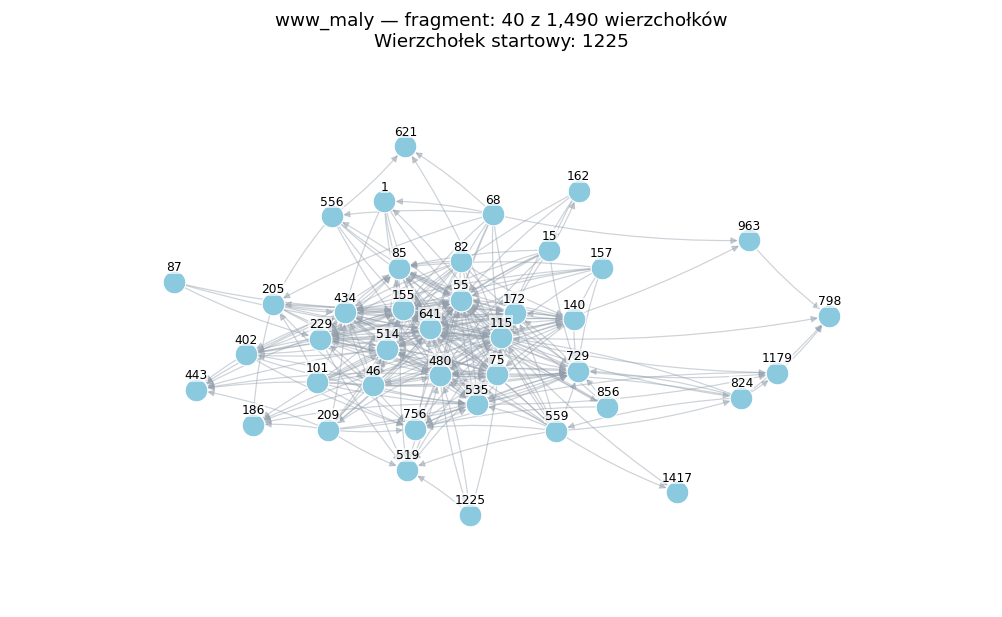

In [13]:
# start: "max_stopień" (największy stopień), "losowy" albo identyfikator wierzchołka.
rysuj_graf(G, start="losowy", max_wierzcholkow=40, tytul=nazwa)
plt.show()


## Stopnie wejściowe i wyjściowe

Stopień wejściowy liczy krawędzie prowadzące **bezpośrednio** do wierzchołka; wyjściowy — wychodzące z niego. Dla naszych grafów nieskierowanych oba stopnie w `D` są równe stopniowi w `G`.

Na wykresach obie osie mają skalę logarytmiczną. Wierzchołki stopnia zero zliczamy osobno. Ta sekcja ma sens dla grafów `maly_www` i `duzy_www`. 


Największe stopnie in: [(155, 337), (1051, 276), (641, 268), (55, 263), (963, 238)]
Największe stopnie out: [(855, 256), (454, 140), (387, 131), (512, 131), (880, 123)]


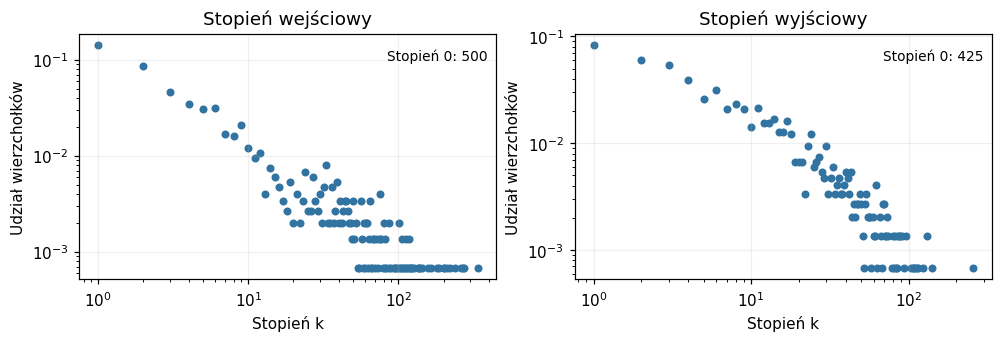

In [ ]:
# Słownik przypisuje każdemu wierzchołkowi jego stopień.
stopnie_in = dict(D.in_degree())
stopnie_out = dict(D.out_degree())

# Porównaj liderów obu rankingów.
for stopnie, opis in [(stopnie_in, "in"), (stopnie_out, "out")]:
    ranking = sorted(stopnie, key=stopnie.get, reverse=True)[:5]
        #sortowanie alternatywnie:
        #ranking = []
        #for v in stopnie:
        #   ranking.append((stopnie[v], v))

        #ranking.sort(reverse=True)
        #ranking = ranking[:5]
    print(f"Największe stopnie {opis}:", [(v, stopnie[v]) for v in ranking])

rysuj_stopnie(D)
plt.show()


## Silnie spójne składowe i kondensacja

NetworkX zwraca składowe jako zbiory wierzchołków. Porządkujemy je według wielkości. W grafie nieskierowanym składowe spójne odpowiadają SCC po zastąpieniu krawędzi parami przeciwnych łuków.

Kondensacja ma po jednym wierzchołku dla każdej SCC. Sprawdzimy, czy rzeczywiście jest DAG-iem. Kolory na rysunku wyróżniają największe składowe; rozmiary na wykresie słupkowym dotyczą **całego** grafu.

Ta sekcja ma sens dla grafów `maly_www` i `duzy_www`. 


Liczba SCC: 688
Rozmiary dziesięciu największych: [793, 3, 2, 2, 2, 2, 2, 2, 2, 2]
Liczba słabo spójnych składowych: 268
Kondensacja: 688 wierzchołków, 666 krawędzi
Czy kondensacja jest DAG-iem? True


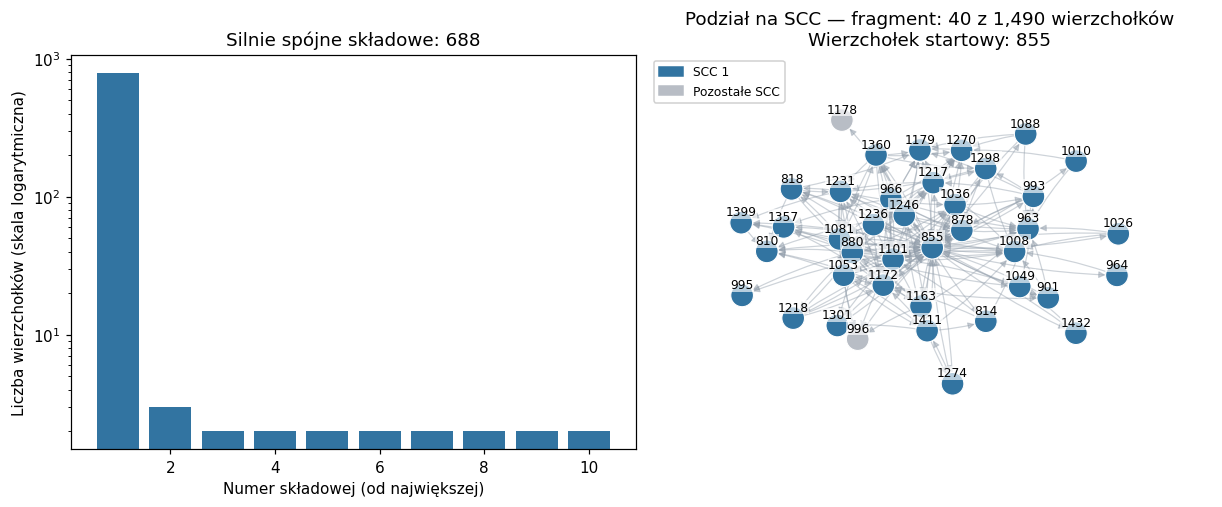

In [15]:
skladowe = sorted(nx.strongly_connected_components(D), key=len, reverse=True)
print("Liczba SCC:", len(skladowe))
print("Rozmiary dziesięciu największych:", [len(C) for C in skladowe[:10]])
print("Liczba słabo spójnych składowych:", nx.number_weakly_connected_components(D))

K = nx.condensation(D, scc=skladowe)
print(f"Kondensacja: {len(K):,} wierzchołków, {K.number_of_edges():,} krawędzi")
print("Czy kondensacja jest DAG-iem?", nx.is_directed_acyclic_graph(K))

rysuj_scc(D, skladowe)
plt.show()


## Zbiory IN i OUT

Wybieramy wierzchołek $v$. Zbiór $\operatorname{In}(v)$ zawiera wierzchołki, z których można dojść do $v$, a $\operatorname{Out}(v)$ — te, do których można dojść z $v$.

Funkcje `nx.ancestors` i `nx.descendants` **nie dodają samego $v$**. Dopisujemy go, zgodnie z definicją z wykładu. Przecięcie IN i OUT powinno być SCC zawierającą $v$. Sprawdź, co zmienia się po wyborze innego wierzchołka.

Ta sekcja ma sens dla grafów `maly_www` i `duzy_www`. 


Wierzchołek: 1
|In_v| = 1,025, |Out_v| = 958, |SCC(v)| = 793
In_v ∩ Out_v jest SCC(v): True
IN = In_v - C: 232; OUT = Out_v - C: 165
Poza In_v i Out_v: 300


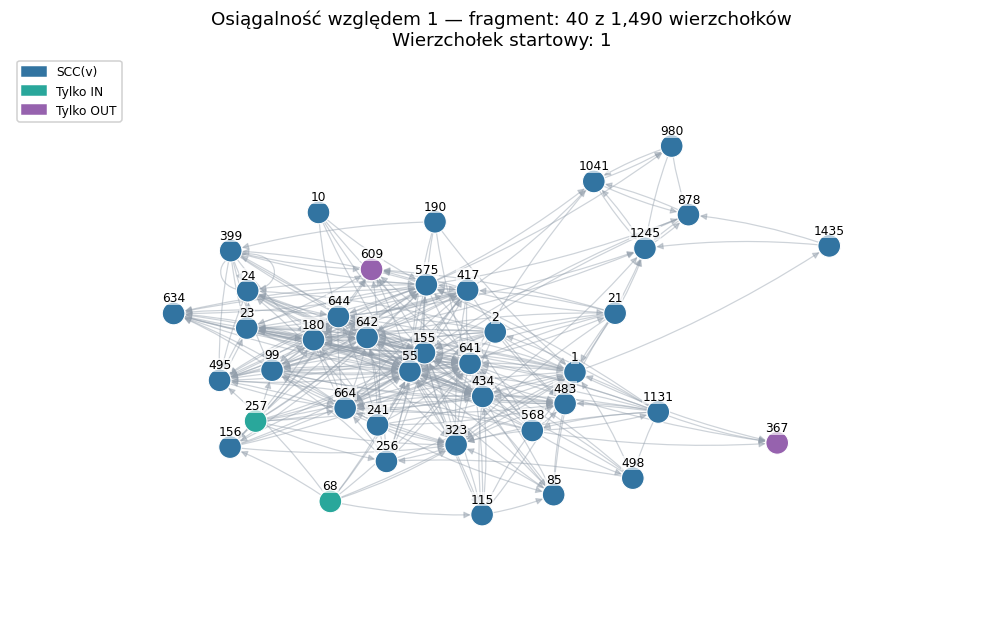

In [16]:
# Na początek wybieramy jeden wierzchołek z największej SCC.
# Zamiast tego możesz wpisać konkretny identyfikator z G.nodes.
v = list(skladowe[0])[0] #albo lepiej: v = next(iter(skladowe[0]))
In_v = nx.ancestors(D, v) | {v}
Out_v = nx.descendants(D, v) | {v}
C = In_v & Out_v

print("Wierzchołek:", v)
print(f"|In_v| = {len(In_v):,}, |Out_v| = {len(Out_v):,}, |SCC(v)| = {len(C):,}")
print("In_v ∩ Out_v jest SCC(v):", C == skladowe[0])
print(f"IN = In_v - C: {len(In_v - C):,}; OUT = Out_v - C: {len(Out_v - C):,}")
print(f"Poza In_v i Out_v: {len(D) - len(In_v | Out_v):,}")

rysuj_zasiegi(D, v, In_v, Out_v)
plt.show()


**Zadanie 1:** Zbadaj dokładniej strukturę grafu `www_maly`. Zobacz jak wyglądają SCC oraz kondensacje podgrafów IN oraz OUT. Zbadaj strukturę `tubes` oraz `tendrils`. Czy ten graf jest spójny?

**Ściągawka do zadania 1**

- `F = D.subgraph(S)` — podgraf indukowany przez zbiór wierzchołków `S`.
- `K = nx.condensation(F)` — kondensacja grafu skierowanego `F`: każda SCC staje się jednym wierzchołkiem.
- `F.number_of_edges()` — liczba krawędzi; działa też dla kondensacji.
- `U = D.to_undirected()` — pominięcie kierunków krawędzi.
- `nx.node_connected_component(U, v)` — zbiór wierzchołków składowej spójnej grafu nieskierowanego `U` zawierającej `v`.
- `nx.weakly_connected_components(D)` — wszystkie słabo spójne składowe grafu skierowanego, jako zbiory wierzchołków.

Po wierzchołkach grafu można iterować, a przez `K.nodes[k]` odczytać słownik danych wierzchołka. W kondensacji atrybut `members` zawiera wierzchołki oryginalnego grafu należące do danej SCC:

```python
for k in K:
    print(k, K.nodes[k])
    print(K.nodes[k]["members"])
```


## Centralność

Najpierw liczymy centralność wektora własnego z wykładu. Jeżeli cały graf nie jest silnie spójny, ograniczamy go do **największej SCC**. Otrzymujemy centralność w tej składowej — nie w całym grafie WWW. Stopnie w poniższym porównaniu również liczymy w tej samej składowej.

[`nx.eigenvector_centrality`](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.eigenvector_centrality.html) stosuje metodę potęgową dla $A+I$, więc możemy jej użyć także w przypadku periodycznym. Zwraca wektor o normie $\ell_2$ równej 1; dzielimy go przez sumę współrzędnych, aby otrzymać normalizację $\ell_1$ z wykładu.


In [ ]:
# copy() daje osobny graf, na którym wielokrotne iteracje są szybsze niż na widoku.
H = D.subgraph(skladowe[0]).copy()
print(f"Badana SCC: {len(H):,} wierzchołków, {H.number_of_edges():,} krawędzi")
print("Czy jest aperiodyczna?", nx.is_aperiodic(H))

# max_iter ogranicza liczbę iteracji; tol ustala tolerancję zakończenia.
# weight=None oznacza, że nie korzystamy z wag zapisanych w danych.
c = nx.eigenvector_centrality(H, max_iter=2000, tol=1e-12, weight=None)
suma = sum(c.values())
c = {v: x / suma for v, x in c.items()}

print("Suma centralności:", sum(c.values()))
# Z cA = lambda*c i sumy c(v)=1 wynika poniższy wzór na lambda.
# Jest to wartość własna A, nie macierzy A+I użytej wewnątrz algorytmu.
lambda_pf = sum(c[v] * H.out_degree(v) for v in H)
print(f"Wartość własna Perrona–Frobeniusa: {lambda_pf:.6f}")


Wierzchołek           Centralność   Stopień in
55                       0.019394          225
155                      0.017914          265
641                      0.017413          217
729                      0.015541          179
642                      0.013380          123
535                      0.012959          102
323                      0.012898          139
180                      0.012502          113
493                      0.012093          111
756                      0.011865          117

Lider centralności: 55
Największy stopień in: 265
Adres blogu lidera: atrios.blogspot.com


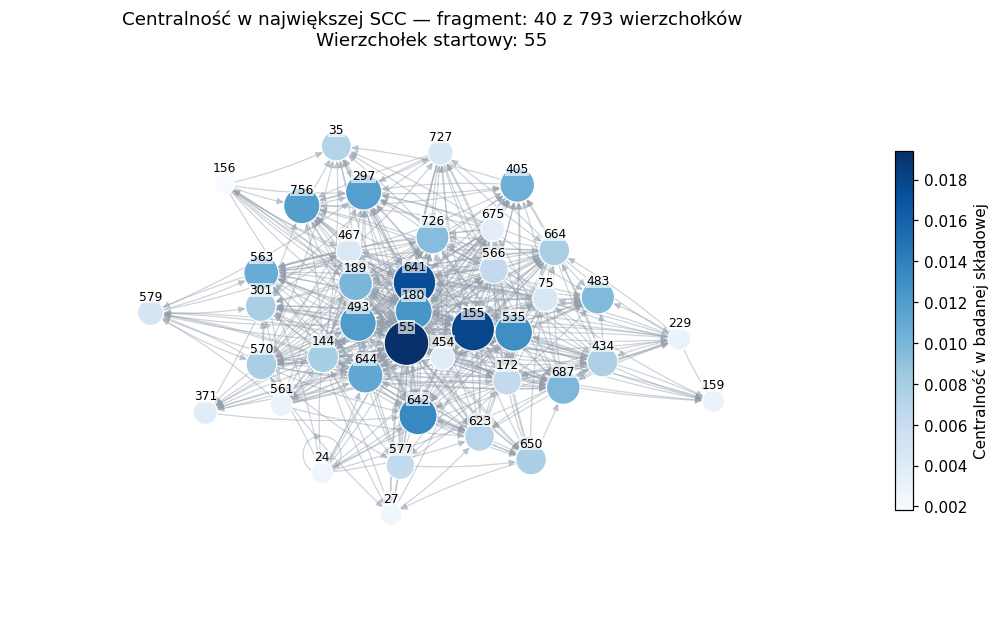

In [17]:
# Porównujemy centralność i stopień wejściowy w H, nie stopień w całym D.
ranking = sorted(c, key=c.get, reverse=True)[:10]
print(f"{'Wierzchołek':<20} {'Centralność':>12} {'Stopień in':>12}")
for v in ranking:
    print(f"{str(v):<20} {c[v]:>12.6f} {H.in_degree(v):>12}")

lider = ranking[0]
print("\nLider centralności:", lider)
print("Największy stopień in:", max(H.in_degree(v) for v in H))
# Dla blogów możemy odczytać adres lidera z atrybutów wierzchołka.
if "label" in H.nodes[lider]:
    print("Adres blogu lidera:", H.nodes[lider]["label"])

# Wielkość i kolor węzła zależą od centralności obliczonej na CAŁYM H.
rysuj_graf(H, start=lider, wartosci=c, tytul="Centralność w największej SCC")
plt.show()


**Zadanie 2:** Znajdź w grafie `florencja` następującą sytuację: po połączeniu pewnych dwóch rodzin, trzecia rodzina, która wcześniej nie miała największej centralności, staje się najbardziej centralna. 

**Ściągawka do zadania 2**

- `c = nx.eigenvector_centrality(F, max_iter=2000, tol=1e-12, weight=None)` — oblicza centralność grafu `F`. Wynik jest słownikiem: `c[v]` to centralność wierzchołka `v`. Tutaj centralność ma normę $\ell_2$ równą 1 (nie jak na wykładzie)
- `F.has_edge(a, b)` — zwraca `True`, jeśli w grafie jest krawędź między `a` i `b`, a w przeciwnym razie `False`.
- `F.add_edge(a, b)` — dodaje krawędź między `a` i `b`, zmieniając graf `F`. Jeśli krawędź już istnieje, w naszym grafie nie powstaje druga.

Jeżeli modyfikujemy wyjściowy graf, dobrze to robić na świerzej kopii: `F_nowy = F.copy()`.


## Macierz i metoda potęgowa — dla małych grafów

Tę część uruchamiamy tylko dla `karate` i `florencja`. Dla dużych sieci nie tworzymy gęstej macierzy: zajmowałaby zbyt wiele pamięci.

Dodanie $I$ odpowiada dodaniu po jednej pętli w każdym wierzchołku i nie zmienia centralności.


In [ ]:
if len(H) <= 50:
    # Kolejność wierzchołków wyznacza kolejność wierszy i kolumn.
    wierzcholki = list(H)
    A = nx.to_numpy_array(H, nodelist=wierzcholki, weight=None, dtype=int)
    
    # Zaczynamy z jednym wirusem w każdym wierzchołku.
    # Normalizacja w każdej rundzie pozwala uniknąć ogromnych liczb.
    alpha = np.ones(len(H)) / len(H)
    B = A + np.eye(len(H))
    cel = np.array([c[v] for v in wierzcholki])
    bledy = [np.linalg.norm(alpha - cel, ord=1)]
    for n in range(60):
        alpha = alpha @ B
        alpha = alpha / np.linalg.norm(alpha, ord=1)
        bledy.append(np.linalg.norm(alpha - cel, ord=1))

    plt.figure(figsize=(7, 3))
    plt.semilogy(bledy, color="#3274a1")
    plt.xlabel("Liczba rund n")
    plt.ylabel("Odległość od centralności w normie ℓ₁")
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("Aby wykonać część macierzową, wybierz karate lub florencja i uruchom notatnik ponownie.")


## PageRank

Teraz zamiast wirusów rozważamy losowego spacerowicza. W centralności wektora własnego ważność wierzchołka trafia do każdego następnego wierzchołka; w PageRanku dzielimy ją przez stopień wyjściowy. Dodatkowo spacerowicz może teleportować się do dowolnego wierzchołka.

Korzystamy z [`nx.pagerank`](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html). Parametr z wykładu $\beta$ nazywa się w tej funkcji `alpha`: z prawdopodobieństwem $\beta$ podążamy za krawędzią, a z prawdopodobieństwem $1-\beta$ teleportujemy się. Domyślnie teleportacja wybiera wierzchołek jednostajnie; tak samo uzupełniane są wierzchołki bez wyjścia. Wynik jest słownikiem, którego wartości sumują się do 1.

PageRank liczymy na **całym `D`**, także gdy nie jest silnie spójny. Nie porównujemy go bezpośrednio z wcześniejszym `c`, obliczonym tylko na największej SCC: byłyby to dwie różne sieci.


In [ ]:
# beta odpowiada parametrowi z wykładu; w NetworkX podajemy alpha=beta.
# Możesz zmienić beta, np. na 0.5 albo 0.95. Tutaj zakładamy 0 < beta < 1.
beta = 0.85
pr = nx.pagerank(D, alpha=beta, weight=None, max_iter=2000, tol=1e-12)

# Pomijamy wagi, tak samo jak przy centralności.
# Dla www_duzy funkcja korzysta z macierzy rzadkiej, nie z gęstej N x N.
print(f"Suma PageRanku: {sum(pr.values()):.6f}")
liderzy_pr = sorted(pr, key=pr.get, reverse=True)[:5]
print(f"{'Wierzchołek':<20} {'PageRank':>12} {'Stopień in':>12}")
for v in liderzy_pr:
    print(f"{str(v):<20} {pr[v]:>12.6f} {D.in_degree(v):>12}")


### Centralność i PageRank na dwóch małych grafach

Pierwszy graf to nieskierowana ścieżka $0-1-2-3-4$. Drugi to graf skierowany na wierzchołkach $A,\ldots,E$. Jest silnie spójny i aperiodyczny: zawiera między innymi cykle długości 3 i 4.

W każdym przykładzie obie miary liczymy na **tym samym grafie** i normalizujemy do sumy 1. Funkcja `rysuj_porownanie` jedynie rysuje graf i otrzymane wartości — obliczenia są widoczne poniżej. Te przykłady nie wymagają pobierania danych.


In [ ]:
# Własne małe grafy: ich definicje można dowolnie modyfikować.
S = nx.path_graph(5)
T = nx.DiGraph([
    ("A", "B"), ("B", "C"), ("C", "A"),  # cykl długości 3
    ("A", "D"), ("D", "E"), ("E", "A"),
    ("B", "D"), ("C", "D"),  # A -> B -> D -> E -> A ma długość 4
])
przyklady = {"Ścieżka nieskierowana": S, "Mały graf skierowany": T}

for opis, F in przyklady.items():
    # NetworkX zwraca centralność z normą ℓ₂=1. Zmieniamy ją na normę ℓ₁=1.
    c_male = nx.eigenvector_centrality(F, max_iter=2000, tol=1e-12, weight=None)
    suma = sum(c_male.values())
    c_male = {v: x / suma for v, x in c_male.items()}
    pr_male = nx.pagerank(F, alpha=beta, weight=None, max_iter=2000, tol=1e-12)

    print(f"\n{opis}, beta = {beta}")
    print(f"{'Wierzchołek':<12} {'Centralność':>12} {'PageRank':>12}")
    for v in F:
        print(f"{str(v):<12} {c_male[v]:>12.4f} {pr_male[v]:>12.4f}")
    rysuj_porownanie(F, {"Centralność": c_male, f"PageRank β={beta}": pr_male},
                     tytul=opis)
    plt.show()


Dla $\beta=0{,}85$ widzimy nie tylko różnice wartości, lecz także innych liderów:

- Na ścieżce największą centralność ma środkowy wierzchołek $2$, ale największy PageRank mają $1$ i $3$. Każdy z nich otrzymuje cały wkład ze skrajnego sąsiada, który ma tylko jedną krawędź wychodzącą.
- W grafie skierowanym centralność wskazuje $D$, a PageRank — $A$. Do $D$ prowadzą trzy krawędzie, lecz $A$, $B$ i $C$ dzielą swój wkład między po dwóch odbiorców. Natomiast $E$ przekazuje cały swój wkład do $A$.

Ważny jest więc nie tylko wybór sąsiadów, lecz także sposób rozdzielania ich ważności.


### Czy teleportacja zmienia wynik?

Dla grafu `T` porównamy PageRank bez teleportacji i z teleportacją. Wyjątkowo używamy `alpha=1`, ponieważ ten konkretny graf jest silnie spójny i aperiodyczny. Nie przenosimy tego ustawienia bez sprawdzenia na inne grafy: na przykład na cyklu iteracje mogą oscylować.

Teleportacja może zmienić zarówno wartości, jak i kolejność w rankingu. To inna operacja niż dodanie po jednej pętli przy obliczaniu centralności, które nie zmieniało jej wektora.


In [ ]:
# Sprawdzamy założenia potrzebne tutaj do iteracji bez teleportacji.
assert nx.is_strongly_connected(T) and nx.is_aperiodic(T)

# Zmień beta_test, aby sprawdzić inną siłę teleportacji.
beta_test = 0.5
warianty = {"Bez teleportacji": 1.0, f"β={beta_test}": beta_test, f"β={beta}": beta}
wyniki_pr = {
    opis: nx.pagerank(T, alpha=b, weight=None, max_iter=2000, tol=1e-12)
    for opis, b in warianty.items()
}
rysuj_porownanie(T, wyniki_pr, tytul="Ten sam graf, różna teleportacja")
plt.show()

# Nawet gdy lider się nie zmienił, cały wektor PageRanku może być inny.
roznica = sum(abs(wyniki_pr["Bez teleportacji"][v] - wyniki_pr[f"β={beta}"][v])
              for v in T)
print(f"Różnica wektorów bez teleportacji i z beta={beta} w normie ℓ₁: {roznica:.6f}")


Na koniec zmień $\beta$ i ponownie uruchom porównania. Dodaj albo usuń jedną krawędź w definicji małego grafu: czy zmienił się lider centralności lub PageRanku? Jeśli graf przestał być silnie spójny, PageRank z teleportacją nadal działa, ale interpretacja centralności z wykładu wymaga ostrożności.

Możesz też obliczyć PageRank na wcześniejszym `H`, czyli największej SCC, i porównać go z `c`. Tym razem obie miary będą dotyczyły dokładnie tej samej sieci.
